<a href="https://colab.research.google.com/github/sushantkumar402/Celsius-to-Fahrenheit-using-ANN/blob/master/Develop_A_Single_Neural_Model_to_convert_Celsius_to_Fahrenheit_using_ANN_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importing required libraries for data processing and visualization
import numpy as np
import tensorflow as tf
from PIL import Image
from google.colab import drive
import matplotlib.pylab as plt

Mounted at /content/drive
(6, 50)
[[4.30475802e-06 9.99999821e-01 9.99999881e-01 1.00000000e+00
  2.75996585e-27 1.09624056e-26 5.82653740e-18 9.99997139e-01
  3.84404242e-09 1.00000000e+00 9.99998987e-01 1.00000000e+00
  5.42601608e-09 2.08189872e-11 1.00000000e+00 1.00000000e+00
  6.11147410e-10 1.31154871e-17 5.81568959e-22 1.80479630e-20
  7.46395881e-06 1.24522038e-19 9.57703139e-10 9.99997675e-01
  4.85773505e-11 9.99999881e-01 1.00000000e+00 8.30153099e-11
  1.05238584e-07 8.12756234e-14 2.70574210e-12 2.59304351e-13
  1.00000000e+00 8.02212504e-14 1.00000000e+00 5.53210839e-07
  2.98187497e-05 1.90833392e-34 4.81108964e-21 8.04194697e-11
  1.00000000e+00 9.99999821e-01 1.12705066e-26 9.99192417e-01
  5.30602557e-21 5.02421883e-36 1.14547469e-10 1.00000000e+00
  5.99765848e-10 2.23856295e-33]
 [4.58294641e-16 1.00000000e+00 1.00000000e+00 1.00000000e+00
  0.00000000e+00 1.10478346e-19 1.39394843e-18 9.99999881e-01
  9.99986529e-01 1.00000000e+00 6.89150470e-09 9.99999881e-01
  6

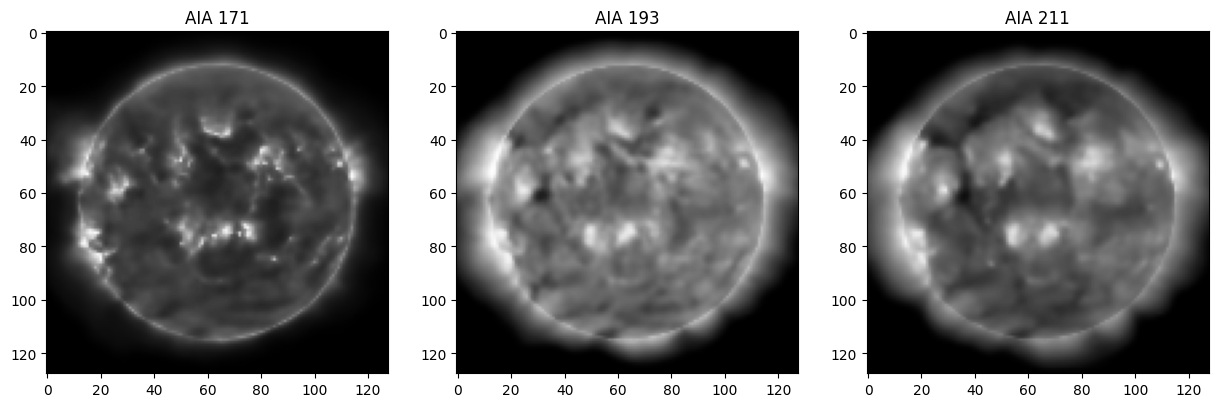

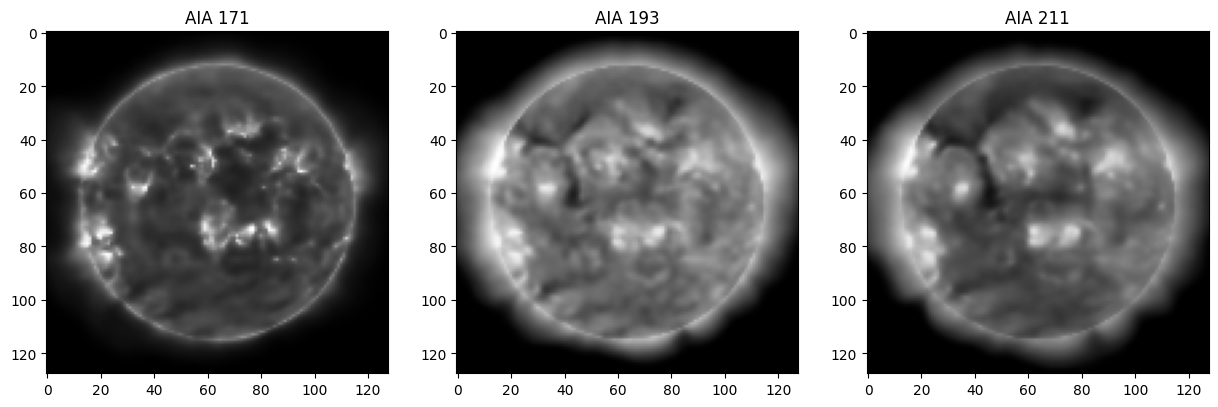

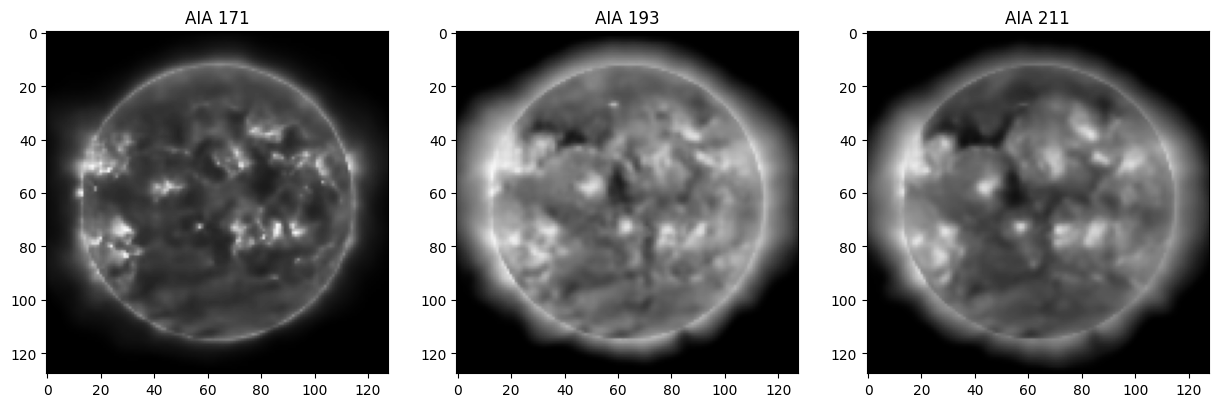

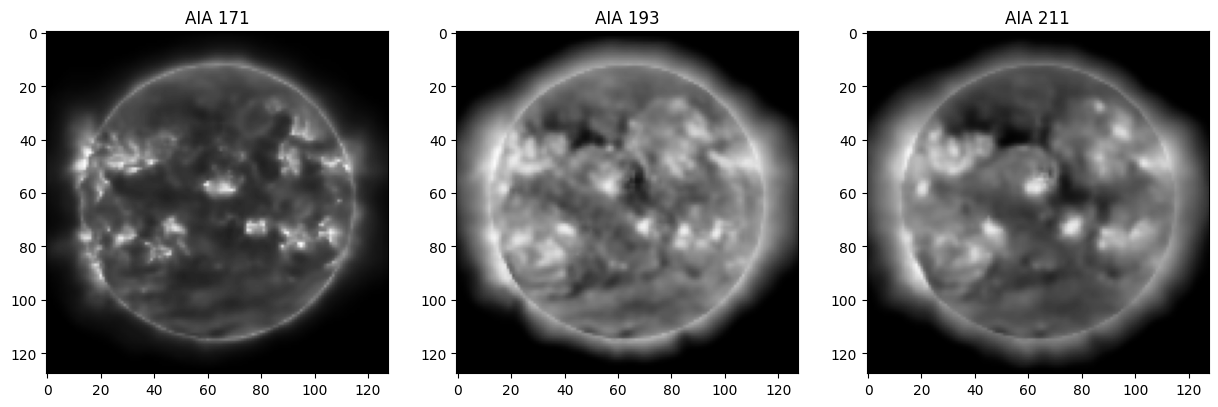

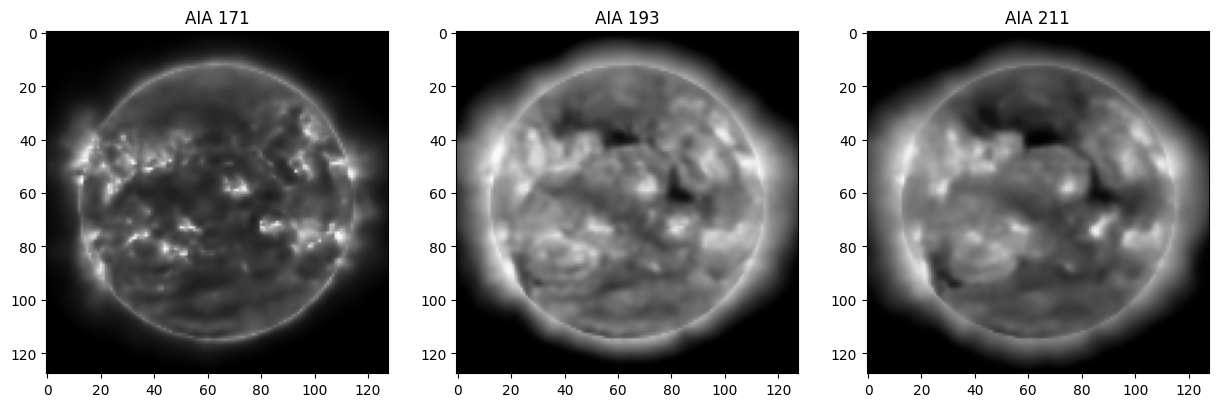

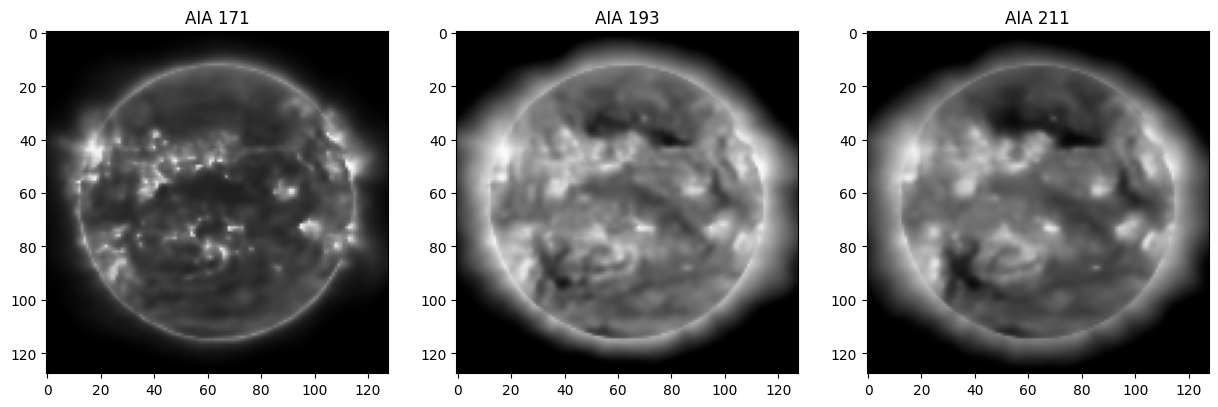

In [ ]:
#Mouting colab with the drive
drive.mount('/content/drive')
base_location = '/content/drive/My Drive/Colab Notebooks/Autoencoder'
# load encoder output
#data = np.loadtxt(base_location+'/output/EncodedVectors.txt',dtype='float32', delimiter=',')

data = np.fromfile(base_location+'/TensorFlow/Sun-VCAE/IO/encoder00006000.dat',dtype='float32', offset=(38*4))
data = np.resize(data,(int((len(data)+3)/53),53))
data = np.delete(data, [50,51,52], 1)
print(data.shape)
print(data)

if len(data.shape) == 1:
    data = data.reshape(1,len(data))
    print(data.shape)

# load decoder model
decoder = tf.keras.models.load_model(base_location+'/TensorFlow/Sun-VCAE/Decoder.h5')

# decompress to 3 wavelengths from latent representation (nx50 array of floats)
d_images = decoder.predict(data)[:,:,:,:,0]

print(d_images.shape)

# denormalize decoder output
d_images *= 255.0
d_images = d_images.astype('int')

# wavelengths that CAE uses
wl = [171,193,211]
# plot outputs
for i in range(d_images.shape[0]):
    axs = (plt.figure(figsize=[15,15]).subplots(1, 3))
    for j in range(len(wl)):
        axs[j].imshow(d_images[i,:,:,j], cmap='gray', vmin=0, vmax=255)
        axs[j].set_title('AIA '+str(wl[j]))
    plt.show()

## Import Libraries

##Decoding images